<a href="https://colab.research.google.com/github/geethat0126-bit/AI_5SEM/blob/main/1BM24CS104_WEEK10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name: GEETHA T
USN: 1BM24CS104

Enter the game tree as nested brackets. Root is MAX; levels alternate MAX, MIN, MAX ...
Example  : [[[10,9],[14,18]],[[5,4],[50,3]]]
Press Enter to use this example.
Tree: [[[3, 5], [6, 9]], [[1, 2], [0, -1]]]

--- Alpha-Beta search ---
MAX node Root: alpha = -inf, beta = inf
    MIN node A: alpha = -inf, beta = inf
        MAX node C: alpha = -inf, beta = inf
            Leaf 3
            Leaf 5
        MAX node D: alpha = -inf, beta = 5
            Leaf 6
          ** PRUNED at D: alpha 6 >= beta 5, skipping 9
    MIN node B: alpha = 5, beta = inf
        MAX node E: alpha = 5, beta = inf
            Leaf 1
            Leaf 2
      ** PRUNED at B: alpha 5 >= beta 2, skipping F

=========== RESULT ===========
Value of root node (MAX) : 5
Path to root value       : Root -> A -> C -> 5
Pruned (cut-off) nodes   : 9, F


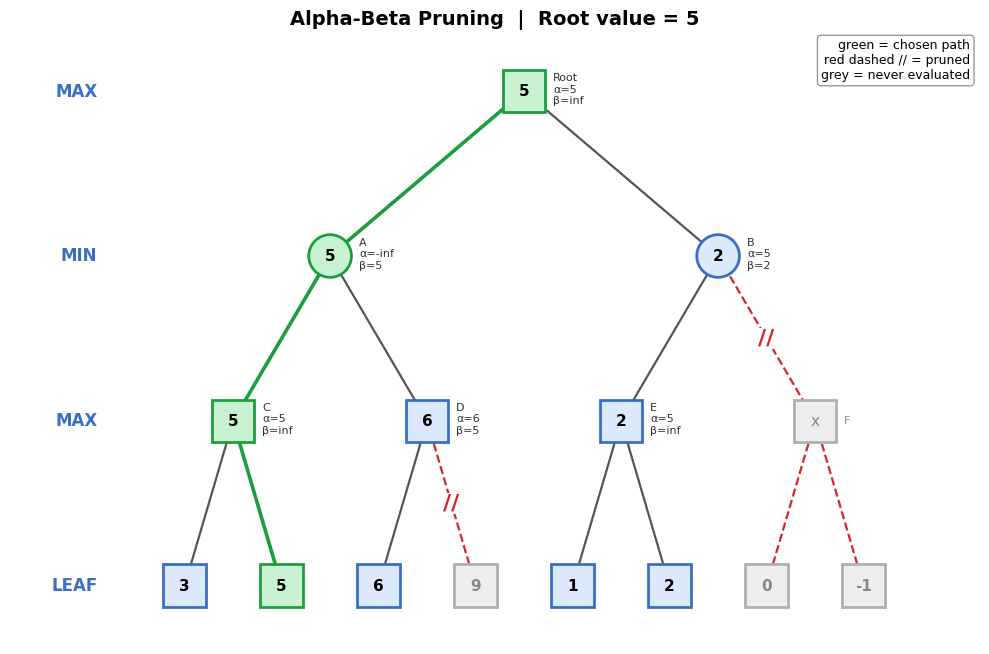

In [1]:
# Week 10 : Alpha-Beta Pruning with user input and tree diagram
print("Name: GEETHA T")
print("USN: 1BM24CS104\n")

import math, ast
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle

class Node:
    def __init__(self, depth):
        self.depth = depth
        self.children = []
        self.value = None          # leaf value, or computed value for internal nodes
        self.name = ""
        self.is_max = (depth % 2 == 0)      # root (depth 0) is MAX
        self.visited = False
        self.alpha = None
        self.beta = None
        self.cut_after = None      # index of last child explored before a cutoff
        self.x = self.y = 0

def build(data, depth=0):
    n = Node(depth)
    if isinstance(data, (int, float)):
        n.value = data
        return n
    if not isinstance(data, list) or len(data) == 0:
        raise ValueError("every bracket [ ] must contain numbers or more brackets")
    n.children = [build(c, depth + 1) for c in data]
    return n

def name_nodes(root):
    """Root, then A, B, C ... (level by level) for internal nodes."""
    letters = [chr(65 + i) for i in range(26)] + [f"N{i}" for i in range(27, 200)]
    level, k = [root], 0
    root.name = "Root"
    while level:
        nxt = []
        for n in level:
            for c in n.children:
                if c.children:
                    c.name = letters[k]; k += 1
                else:
                    c.name = str(c.value)
                nxt.append(c)
        level = nxt

def alpha_beta(node, alpha, beta, depth=0):
    ind = "    " * depth
    node.visited = True
    node.alpha, node.beta = alpha, beta
    if not node.children:
        print(f"{ind}Leaf {node.value}")
        return node.value, [node]
    kind = "MAX" if node.is_max else "MIN"
    print(f"{ind}{kind} node {node.name}: alpha = {alpha}, beta = {beta}")
    best = -math.inf if node.is_max else math.inf
    best_path = []
    for i, ch in enumerate(node.children):
        v, p = alpha_beta(ch, alpha, beta, depth + 1)
        if node.is_max:
            if v > best: best, best_path = v, [node] + p
            alpha = max(alpha, best)
        else:
            if v < best: best, best_path = v, [node] + p
            beta = min(beta, best)
        node.alpha, node.beta = alpha, beta
        if alpha >= beta:
            if i < len(node.children) - 1:
                node.cut_after = i
                cut = ", ".join(c.name for c in node.children[i + 1:])
                print(f"{ind}  ** PRUNED at {node.name}: alpha {alpha} >= beta {beta}, skipping {cut}")
            break
    node.value = best
    return best, best_path

def layout(root):
    leaves = [0]
    def go(n):
        if not n.children:
            n.x = leaves[0]; leaves[0] += 1
        else:
            for c in n.children: go(c)
            n.x = sum(c.x for c in n.children) / len(n.children)
        return n
    go(root); return leaves[0]

def all_nodes(n):
    yield n
    for c in n.children: yield from all_nodes(c)

def draw(root, path, title):
    nleaf = layout(root)
    depth = max(n.depth for n in all_nodes(root))
    fig, ax = plt.subplots(figsize=(max(9, nleaf * 1.0 + 2), 1.9 * (depth + 1) + 1))
    YS = 1.7
    on_path = set(id(n) for n in path)
    GREEN, RED, GREY, BLUE = "#1b9e3e", "#d62728", "#b0b0b0", "#3a6fc4"

    # Edges
    for n in all_nodes(root):
        for i, c in enumerate(n.children):
            pruned = (not c.visited)
            col = RED if pruned else (GREEN if id(n) in on_path and id(c) in on_path else "#555")
            ax.plot([n.x, c.x], [-n.depth*YS, -c.depth*YS], color=col, lw=2.6 if col == GREEN else 1.6,
                    ls="--" if pruned else "-", zorder=1)
            if pruned and n.cut_after is not None and i == n.cut_after + 1:
                mx, my = (n.x + c.x) / 2, (-n.depth*YS - c.depth*YS) / 2
                ax.text(mx, my, "//", color=RED, fontsize=16, fontweight="bold", ha="center", va="center",
                        bbox=dict(fc="white", ec="none", pad=0.5), zorder=3)

    # Nodes
    for n in all_nodes(root):
        if not n.visited:
            fc, ec = "#eeeeee", GREY
        elif id(n) in on_path:
            fc, ec = "#c9f2d3", GREEN
        else:
            fc, ec = "#dce8fb", BLUE
        sq = n.is_max or not n.children
        r = 0.22
        if sq:
            ax.add_patch(Rectangle((n.x - r, -n.depth*YS - r), 2 * r, 2 * r, fc=fc, ec=ec, lw=2, zorder=2))
        else:
            ax.add_patch(Circle((n.x, -n.depth*YS), r, fc=fc, ec=ec, lw=2, zorder=2))
        if not n.children:
            ax.text(n.x, -n.depth*YS, str(n.value), ha="center", va="center", fontsize=11, fontweight="bold",
                    color="#888" if not n.visited else "black", zorder=4)
        else:
            if n.visited:
                ax.text(n.x, -n.depth*YS, str(n.value), ha="center", va="center", fontsize=11, fontweight="bold", zorder=4)
                a = "-inf" if n.alpha == -math.inf else n.alpha
                b = "inf" if n.beta == math.inf else n.beta
                ax.text(n.x + 0.3, -n.depth*YS + 0.02, f"{n.name}\n\u03b1={a}\n\u03b2={b}", ha="left", va="center",
                        fontsize=8, color="#333", zorder=4)
            else:
                ax.text(n.x, -n.depth*YS, "x", ha="center", va="center", fontsize=11, color="#888", zorder=4)
                ax.text(n.x + 0.3, -n.depth*YS, n.name, ha="left", va="center", fontsize=8, color="#888", zorder=4)

    # Level labels
    for d in range(depth + 1):
        only_leaves = all(not n.children for n in all_nodes(root) if n.depth == d)
        lab = "LEAF" if only_leaves else ("MAX" if d % 2 == 0 else "MIN")
        ax.text(-0.9, -d*YS, lab, fontsize=12, fontweight="bold",
                color=BLUE, ha="right", va="center")

    ax.text(0.99, 0.99, "green = chosen path\nred dashed // = pruned\ngrey = never evaluated",
            transform=ax.transAxes, ha="right", va="top", fontsize=9,
            bbox=dict(fc="white", ec="#999", boxstyle="round"))
    ax.set_xlim(-1.8, nleaf + 0.2); ax.set_ylim(-depth*YS - 0.6, 0.6); ax.set_aspect('equal')
    ax.axis("off"); ax.set_title(title, fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()

def read_tree():
    print("Enter the game tree as nested brackets. Root is MAX; levels alternate MAX, MIN, MAX ...")
    print("Example  : [[[10,9],[14,18]],[[5,4],[50,3]]]")
    print("Press Enter to use this example.")
    while True:
        s = input("Tree: ").strip()
        if s == "":
            s = "[[[10,9],[14,18]],[[5,4],[50,3]]]"
            print("Using:", s)
        try:
            return build(ast.literal_eval(s))
        except Exception as e:
            print("Invalid tree (", e, "). Check brackets/commas and try again.")

if __name__ == "__main__":
    root = read_tree()
    name_nodes(root)
    if not root.children:
        print("The tree must have at least one level."); raise SystemExit

    print("\n--- Alpha-Beta search ---")
    value, path = alpha_beta(root, -math.inf, math.inf)

    pruned = [c.name for n in all_nodes(root) if n.visited for c in n.children if not c.visited]
    print("\n=========== RESULT ===========")
    print("Value of root node (MAX) :", value)
    print("Path to root value       :", " -> ".join(n.name if n.children else str(n.value) for n in path))
    print("Pruned (cut-off) nodes   :", ", ".join(pruned) if pruned else "None")
    draw(root, path, f"Alpha-Beta Pruning  |  Root value = {value}")
